<a href="https://colab.research.google.com/github/Dulce946/M-todos-Numericos-1/blob/main/Metodo_Biseccion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Método de Bisección

**Estudiante:** Dulce Maria Melchor Dávila

**Materia:** Métodos númericos

El **Método de Bisección** es un algoritmo iterativo basado en el **Teorema del Valor Intermedio**. Este teorema establece que si una función $f(x)$ es continua en un intervalo cerrado $[a,b]$ y los signos de  la función en los extremos son opuestos, es decir:

$$f(a) \cdot f(b) < 0$$

Entonces, obligatoriamente existe al menos un valor  $p \in (a,b)$ tal que $f(p) = 0$. En otras palabras el intervalocontiene al menos una raíz real.

### El algoritmo
El método consiste en dividir respectivamente el intervalo a la mitad mediante el cálculo de su punto medio $p_n$:

$$p_n=a_n +  \frac{b_n - a_n}{2}$$

Luego, se evalua el  signo de $f(p_n)$ para determinar en cúal de los dos subintervalos ($[a,p_n]$ o $[p_n,b]$) ocurre el cambio de signo, redefiniendo los límites para la siguiente iteración. Este proceso se repite hasta que se cumpla una tolerancia preestablecida $\epsilon$ o se alcance un número máximo de iteraciones $N_{max}$.  

In [1]:
import numpy as np                  #Para operacionesmatemáticas y arreglos númericos
import matplotlib.pyplot as plt     #Para generar graficas del problema
import pandas as pd                 #Para organizar los resultados en tablas estilizadas

##Ejemplo 1 (Burden, pág. 38)

Pra validar la correcta implementación del algoritmo, resolveremos el **Ejemplo 1**, el cual solicita encontrar la raíz  de la siguiente ecuación:

$$f(x) = x^3 + 4x^2 - 10 =0$$

Dentro del intervalo cerrado $[1, 2]$.

##Verificación inicial de Signos:
*Evaluando el límite: $f(1) = (1)= (1)^3 + 4(1)^2 - 10 = -5 \quad (< 0)$

*Evaluando el límite: $f(2) = (2)= (2)^3 + 4(2)^2 - 10 = 14 \quad (> 0)$

Como $f(1) \cdot f(2) = -70 < 0$, se garantiza la existencia de la raíz en este intervalo.

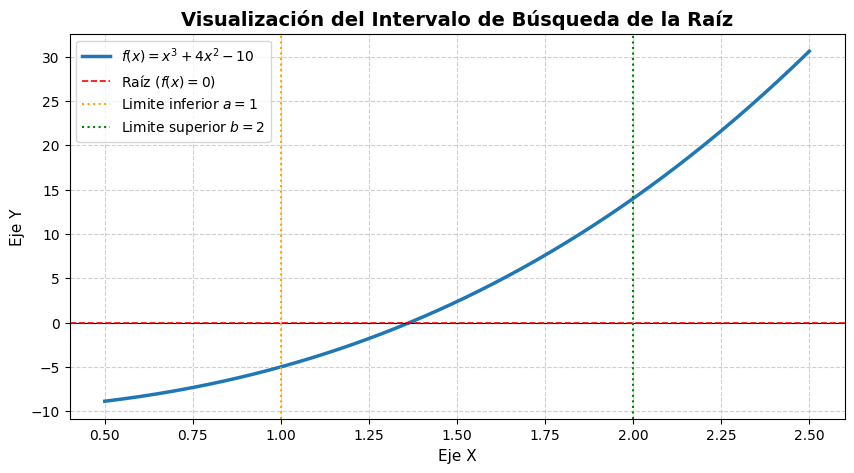

In [6]:
# Definimios la función matemática del problema
def f(x):
    return x**3 + 4*x**2 - 10

#Generamos 200 puntos distribuidos para trazar la curva
x_valores = np.linspace(0.5, 2.5, 200)
y_valores = f(x_valores)

#Creamos el lienzo de la gráfica
plt.figure(figsize=(10, 5))
plt.plot(x_valores, y_valores, color='#1f77b4', linewidth=2.5, label='$f(x) = x^3 + 4x^2 - 10$')

#Agregamos líneas guía intersecando los ejes y los límites del intervalo
plt.axhline(0, color='black', linestyle='-', linewidth=0.8) #Eje X
plt.axhline(0, color='red', linestyle='--', linewidth=1.2, label='Raíz ($f(x)=0$)')
plt.axvline(1, color='orange', linestyle=':', linewidth=1.5, label='Limite inferior $a=1$')
plt.axvline(2, color='green', linestyle=':', linewidth=1.5, label='Limite superior $b=2$')

#Titulos y etiquetas de los ejes
plt.title('Visualización del Intervalo de Búsqueda de la Raíz', fontsize=14, fontweight='bold')
plt.xlabel('Eje X', fontsize=11)
plt.ylabel('Eje Y', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper left')

#Desplegar la gráfica
plt.show()

In [13]:
def metodo_biseccion(f, a, b, tol, max_iter):
    """
    Implementación del algoritmo 2.1 del libro de Burden.
    """

    #Verificar la condición del Teorema del Valor Intermedio
    if f(a) * f(b) >=0:
       raise ValueError("Error: f(a) y f(b) deben tener signos opuestos.")

    #Inicialización del contador de iteraciones y de la variable FA
    i = 1
    FA = f(a)

    #Lista para almacenar el historial de datos y poder estructurar la tabla al final
    historial = []

    #Iniciar el bucle iterativo principal
    while i<= max_iter:

      #Calcular el punto medio con presición para evitar errores de redondeo
      p = a + (b - a) / 2.0
      FP = f(p)

      #Calculamos el error estimado actual(la mitad del intervalo restante)
      error_estimado = (b - a) / 2.0

      #Registramos las variables calculadas en la lista del historial
      historial.append({
          'Iteración': i,
          'a': a,
          'b': b,
          'Punto medio (p)': p,
          'f(p)': FP,
          'Error estimado': error_estimado
      })

      #Comprobar los criterios de parada (si f(p) es exactamente cero o si si logramos la tolerancia)
      if FP == 0 or error_estimado < tol:
         #Convertimos el historial acumulado en un DataFrame de Pandas
         tabla_df = pd.DataFrame(historial)
         return p, tabla_df

      #Incrementar el contador de iteraciones si el criterio no se cumplió
      i += 1

      #Determinar el nuevo subintervalo basándonos en el teorema de signos
      if FA * FP > 0:
         a = p                #La raíz  se encuentra en la mitad derecha, actualizamos el limite inferior
         FA = FP              #Actualizamos el valor de la función para el nuevo limite
      else:
         b = p                #La raíz  se encuentra en la mitad izquierda, actualizamos el limite superior

    # Mensaje de error si se agotan las iteraciones permitidas sin converger
    raise RuntimeError(f"El método no logro conver después de {max_iter} iteraciones.")

In [14]:
#Definición de parámetros iniciales del ejemplo 1 de Burden
limite_a = 1.0
limite_b = 2.0
tolerancia_epsilon = 1e-4      #Esto equivale a 10^-4 o 0.0001
iteraciones_maximas = 20

#Llamamos a nuestra función de bisección pasándole los parámetros
raiz_final, tabla_convergencia = metodo_biseccion(f, limite_a, limite_b, tolerancia_epsilon, iteraciones_maximas)

#Imprimimos y visualizamos la tabla ocultando los índices de fila y dando formato numérico
print("Ejecución del algoritmo\n")

#Estilizamos la tabla ocultando los índices de fila y dando formato numérico
tabla_convergencia.style.hide(axis='index').format({
     'a': '{:.6f}',
     'b': '{:.6f}',
     'Punto medio (p)': '{:.6f}',
     'f(p)': '{:.6f}',
     'Error estimado': '{:.6f}'
})

Ejecución del algoritmo



Iteración,a,b,Punto medio (p),f(p),Error estimado
1,1.000000,2.000000,1.500000,2.375000,0.500000
2,1.000000,1.500000,1.250000,-1.796875,0.250000
3,1.250000,1.500000,1.375000,0.162109,0.125000
4,1.250000,1.375000,1.312500,-0.848389,0.062500
5,1.312500,1.375000,1.343750,-0.350983,0.031250
6,1.343750,1.375000,1.359375,-0.096409,0.015625
7,1.359375,1.375000,1.367188,0.032356,0.007812
8,1.359375,1.367188,1.363281,-0.032150,0.003906
9,1.363281,1.367188,1.365234,0.000072,0.001953
10,1.363281,1.365234,1.364258,-0.016047,0.000977


## Conclusiones y resultados finales

Al analizar la tabla de convergencia iterativa generada por el programa, se puede puntualizar las siguientes conclusiones:

1. **Convergencia exitosa:** El método cumplión satisfactoriamente con el criterio de parada en la **iteración número 13**, debido a que el error estimado en ese punto pasó a ser $6.1035 \times 10^{-5}$, cumpliendo con ser menor a la tolerancia solicitada de $\epsilon = 10^{-4}$.
2. **Aproximación de la raíz:** La aproximación final obtenida para el valor de la raíz es:

$$\mathbf{p \approx 1.365112}$$

3. **Validación teórica:** El resultado númerico arrojado y el comportamiento en cada paso coinciden exactamente de inicio a fin con los datos expuestos en la **Tabla 2.1 de la página 38** del libro de Burden.